#IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# models
from sklearn.ensemble import RandomForestRegressor

# evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#LOAD DATASET


In [2]:
# load dataset
df = pd.read_csv("housing.csv")

# display first rows
print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


#EXPLORE DATASET


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


#HANDLE MISSING VALUES

In [8]:
df["total_bedrooms"].fillna(df["total_bedrooms"].mean(),inplace=True)

/tmp/ipykernel_5782/3288458331.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["total_bedrooms"].fillna(df["total_bedrooms"].mean(),inplace=True)


#FEATURE SELECTION

In [9]:
X = df.drop("median_house_value",axis=1)
y = df["median_house_value"]

#SEPERATE NUMERICAL & CATEGORICAL COLUMN

In [10]:
categorical_cols = ["ocean_proximity"]

numerical_cols = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

#PREPROCESSING PIPELINE


In [11]:
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

Train Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Bulid ML Pipeline

In [13]:
RFR = RandomForestRegressor(
  n_estimators=100,
  criterion="squared_error",
  max_depth=None,
  min_samples_split=2,
  min_samples_leaf=1,
  random_state=42
)

PL = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RFR)
])


Train the Model


In [14]:
PL.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

Make Prediction

In [15]:
y_pred = PL.predict(X_test)

#EVALUATE MODEL

Mean Absolute Error

In [16]:
MAE = mean_absolute_error(y_test, y_pred)
print("MAE:", MAE)

MAE: 31667.989481589146


Mean Square Error

In [17]:
MSE = mean_squared_error(y_test, y_pred)
print("MSE:", MSE)

MSE: 2397315306.588798


Root Mean Square Error

In [18]:
RMSE = np.sqrt(MSE)
print("RMSE:", RMSE)

RMSE: 48962.386651273424


r2_score

In [19]:
R2 = r2_score(y_test, y_pred)
print("R2:", R2)

R2: 0.8170559461667481


#Feature Importance

In [23]:
RFR = PL.named_steps["regressor"]

importances = RFR.feature_importances_

print(importances)

[1.05888954e-01 1.01596825e-01 5.19353675e-02 2.33658439e-02
 2.38185139e-02 3.25732010e-02 1.83666222e-02 4.90641983e-01
 3.38614792e-03 1.40924510e-01 4.54844961e-04 7.11388306e-04
 6.33579797e-03]


#VISUALIZATION

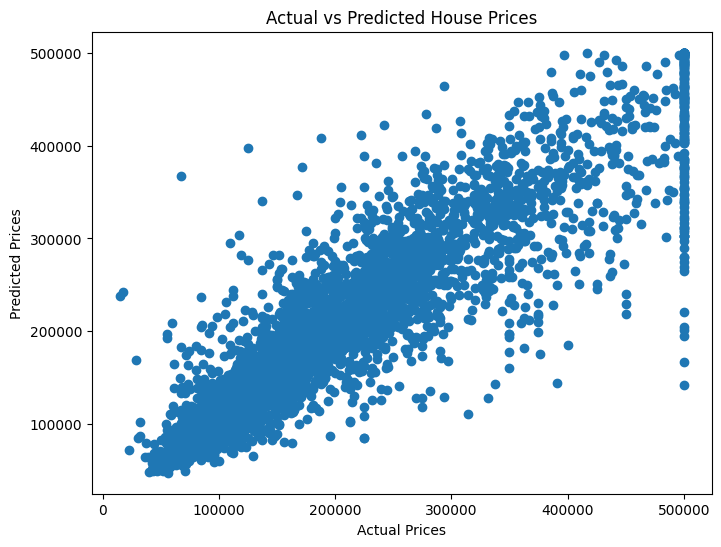

In [24]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

#EXAMPLE

In [26]:
sample = pd.DataFrame({
    "longitude": [-122.23],
    "latitude": [37.88],
    "housing_median_age": [41],
    "total_rooms": [880],
    "total_bedrooms": [129],
    "population": [322],
    "households": [126],
    "median_income": [8.3252],
    "ocean_proximity": ["NEAR BAY"]
})

prediction = PL.predict(sample)

print("Predicted House Price:", prediction[0])

Predicted House Price: 431942.36
